<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

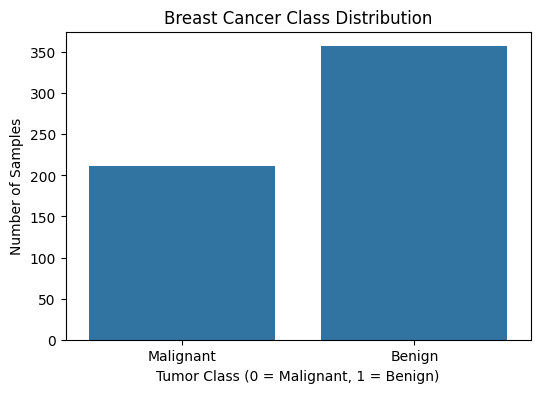

Dimensi Train & Test: (398, 30) (171, 30)
              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.9883     0.9907  0.9907    0.9907   0.9981
      Random Forest    0.9357     0.9444  0.9533    0.9488   0.9913

=== Classification Report: Logistic Regression ===
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171


=== Classification Report: Random Forest ===
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171

Lo

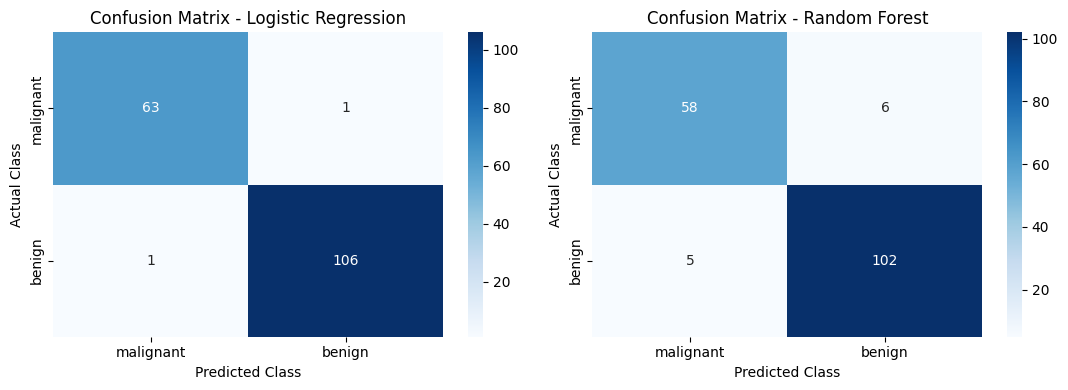

In [ ]:
# ===== 1. Import library =====
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

# ===== 2. Informasi dataset =====
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")
X.info()
print("Missing values:", X.isnull().sum().sum())

# ===== 3. Distribusi kelas =====
print(y.value_counts())
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.xticks([0, 1], ["Malignant", "Benign"])
plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.savefig("class_distribution.png", bbox_inches="tight")
plt.show()

# ===== 4. Split data 70:30 =====
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
print("Dimensi Train & Test:", X_train.shape, X_test.shape)

# ===== 5. Training model =====
# Logistic Regression memakai data yang di-scale
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_s, y_train)

# Random Forest memakai data asli (tanpa scaling)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

pred_lr = lr.predict(X_test_s)
pred_rf = rf.predict(X_test)
proba_lr = lr.predict_proba(X_test_s)[:, 1]
proba_rf = rf.predict_proba(X_test)[:, 1]

# ===== 6. Tabel perbandingan =====
def evaluate(nama, y_true, pred, proba):
    return {"Model": nama,
            "Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred),
            "F1-score": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, proba)}

hasil = pd.DataFrame([
    evaluate("Logistic Regression", y_test, pred_lr, proba_lr),
    evaluate("Random Forest", y_test, pred_rf, proba_rf)])
print(hasil.round(4).to_string(index=False))

# ===== 7. Classification report =====
for nama, pred in [("Logistic Regression", pred_lr), ("Random Forest", pred_rf)]:
    print(f"\n=== Classification Report: {nama} ===")
    print(classification_report(y_test, pred, target_names=data.target_names))

# ===== 8. Confusion matrix =====
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, judul in zip(axes, [pred_lr, pred_rf],
                           ["Logistic Regression", "Random Forest"]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=data.target_names,
                yticklabels=data.target_names, ax=ax)
    ax.set_title(f"Confusion Matrix - {judul}")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    print(f"{judul}: malignant lolos (diprediksi benign) = {cm[0][1]}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", bbox_inches="tight")
plt.show()

## Analisis Hasil

**Model yang lebih baik: Logistic Regression.**
Logistic Regression unggul pada semua metrik: accuracy 98.83% (vs 93.57%), recall 0.9907 (vs 0.9533), F1-score 0.9907 (vs 0.9488), dan ROC-AUC 0.9981 (vs 0.9913). Pada confusion matrix, Logistic Regression hanya meloloskan **1** kasus malignant yang diprediksi benign, sedangkan Random Forest meloloskan **6** kasus.

## Mengapa Accuracy Saja Tidak Cukup pada Klasifikasi Kanker?

1. **Accuracy tidak membedakan jenis kesalahan.** Tumor ganas yang diprediksi jinak (bisa menunda pengobatan) jauh lebih berbahaya daripada sebaliknya, padahal accuracy menghitung keduanya sama.
2. **Data tidak seimbang** (212 malignant vs 357 benign), sehingga accuracy bisa tampak tinggi walau kelas minoritas kurang terdeteksi.
3. **Recall** menunjukkan seberapa banyak kasus kanker yang berhasil terdeteksi, **precision** menunjukkan ketepatan prediksi positif, dan **F1-score** menyeimbangkan keduanya.
4. **Confusion Matrix** memperlihatkan jumlah kesalahan per jenis (FN dan FP) secara langsung.

## Kesimpulan

Logistic Regression memberi hasil klasifikasi lebih baik pada dataset ini, baik dari accuracy maupun jumlah kasus malignant yang lolos. Hasil ini berasal dari satu pembagian data (`random_state=42`), dan model hanya untuk pembelajaran, bukan diagnosis medis.